In [ ]:
import tensorflow as tf
import numpy as np
from IPython.core import history
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, AveragePooling2D

In [ ]:
(x_train, y_train),(x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Trainig data",x_train.shape)
print("Testing data",x_test.shape)

Trainig data (60000, 28, 28)
Testing data (10000, 28, 28)


In [ ]:
x_train=x_train/255.0
x_test=x_test/255.0

In [ ]:
x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)
print("Trainig data",x_train.shape)
print("Testing data",x_test.shape)

Trainig data (60000, 28, 28, 1)
Testing data (10000, 28, 28, 1)


In [ ]:
model=Sequential([
    layers.Conv2D(filters=6, kernel_size=(5,5), activation='tanh', input_shape=(28,28,1)),
    layers.AveragePooling2D(pool_size=(2,2), strides=2),
    layers.Conv2D(filters=16, kernel_size=(5,5), activation='tanh'),
    layers.AveragePooling2D(pool_size=(2,2), strides=2),
    layers.Flatten(),
    #fully connected layers
    layers.Dense(units=120, activation='tanh'),
    layers.Dense(units=84, activation='tanh'),
    #output layers
    layers.Dense(units=10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
history=model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.8862 - loss: 0.3882 - val_accuracy: 0.9585 - val_loss: 0.1522
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.9558 - loss: 0.1483 - val_accuracy: 0.9732 - val_loss: 0.0965
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.9712 - loss: 0.0964 - val_accuracy: 0.9788 - val_loss: 0.0778
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.9771 - loss: 0.0739 - val_accuracy: 0.9802 - val_loss: 0.0669
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.9813 - loss: 0.0596 - val_accuracy: 0.9825 - val_loss: 0.0606
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.9844 - loss: 0.0493 - val_accuracy: 0.9842 - val_loss: 0.0525
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.9875 - loss: 0.0418 - val_accuracy: 0.9852 - val_loss: 0.0518
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.9896 - loss: 0.0350 - 

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test accuracy:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9837 - loss: 0.0497
Test accuracy: 0.9836999773979187


In [ ]:
predictions=model.predict(x_test)
print("Pridicted digit:", predictions[0].argmax())
print("Actual digit:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Pridicted digit: 7
Actual digit: 7


<function matplotlib.pyplot.axis(arg: 'tuple[float, float, float, float] | bool | str | None' = None, /, *, emit: 'bool' = True, **kwargs) -> 'tuple[float, float, float, float]'>

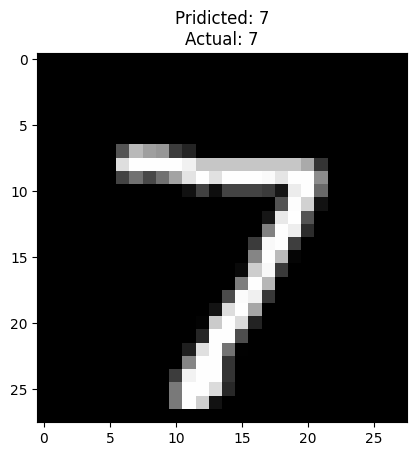

In [ ]:
plt.imshow(x_test[0].reshape(28,28), cmap='gray')
plt.title(
    f"Pridicted: {predictions[0].argmax()}\n"
    f"Actual: {y_test[0]}"
)
plt.axis